Dataset Shape: (168, 1)

First 3 rows:
             Production
Date                  
1962-01-01         589
1962-02-01         561
1962-03-01         640

Missing Values: {'Production': 0}

Training sequences shape: (132, 12, 1)
Testing sequences shape:  (24, 12, 1)

Training RNN Model...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 573ms/step

Training LSTM Model...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 579ms/step

Training GRU Model...
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 672ms/step

=== Model Performance Comparison ===


,Model,MAE,RMSE,MAPE (%)
0,RNN,9.681104,11.726615,1.133432
1,LSTM,21.217814,25.630767,2.484392
2,GRU,20.300504,25.186085,2.396174


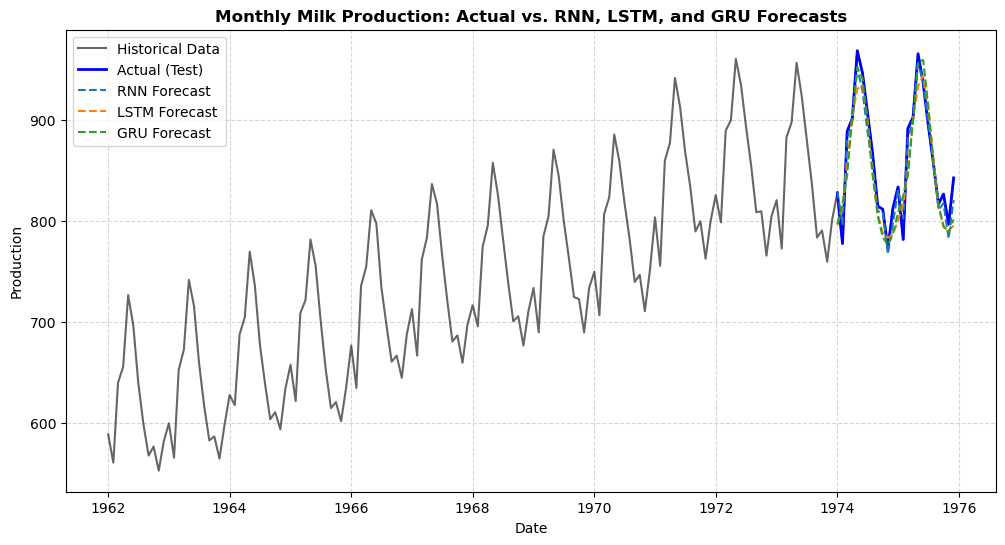

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 696ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step

=== Next 12 Months Milk Production Forecast (LSTM) ===


,Forecasted_Production
Date,
1976-01-31,810.512939
1976-02-29,817.985168
1976-03-31,859.001343
1976-04-30,890.116943
1976-05-31,916.158203
1976-06-30,910.776917
1976-07-31,887.923950
1976-08-31,854.789673
1976-09-30,821.010254


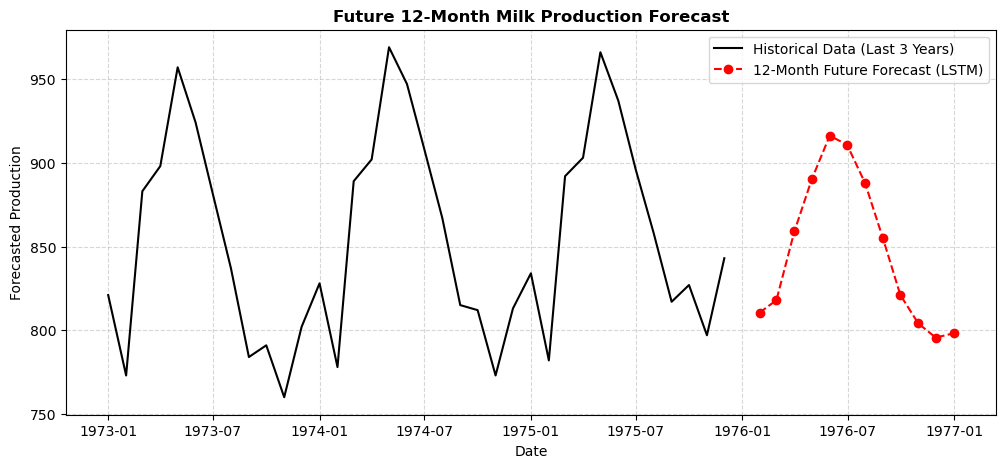

In [1]:
# Assignment 20: Monthly Milk Production Forecasting 
# Using RNN, LSTM, and GRU Deep Learning Models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Ensure full reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Step 1 & 2: Data Exploration & Preparation
# 1. Load Dataset
df = pd.read_csv('monthly_milk_production.csv')
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))
print("\nMissing Values:", df.isnull().sum().to_dict())

# 2. Data Scaling (Normalization between 0 and 1 for Neural Networks)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['Production']])

# 3. Create Time Windows (Sequences)
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

WINDOW_SIZE = 12  # Using past 12 months (1 year) to predict the next month
X, y = create_sequences(scaled_data, WINDOW_SIZE)

# Reshape X for RNN/LSTM/GRU input: [samples, time steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# 4. Train-Test Split (Train on past data, test on the last 24 months)
test_size = 24
train_size = len(X) - test_size

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"\nTraining sequences shape: {X_train.shape}")
print(f"Testing sequences shape:  {X_test.shape}")


# Step 3: Model Building (RNN, LSTM, GRU)
def compile_model(model_type):
    model = Sequential()
    model.add(Input(shape=(WINDOW_SIZE, 1)))
    
    if model_type == 'RNN':
        model.add(SimpleRNN(50, activation='tanh', return_sequences=False))
    elif model_type == 'LSTM':
        model.add(LSTM(50, activation='tanh', return_sequences=False))
    elif model_type == 'GRU':
        model.add(GRU(50, activation='tanh', return_sequences=False))
        
    model.add(Dense(25, activation='relu'))
    model.add(Dense(1)) # Predict next month production
    
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')
    return model

# Train and evaluate models
models = {}
predictions = {}
metrics_results = []

early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

for m_name in ['RNN', 'LSTM', 'GRU']:
    print(f"\nTraining {m_name} Model...")
    model = compile_model(m_name)
    model.fit(X_train, y_train, epochs=100, batch_size=16, callbacks=[early_stop], verbose=0)
    
    # Predict on test set
    scaled_preds = model.predict(X_test)
    preds = scaler.inverse_transform(scaled_preds)
    actuals = scaler.inverse_transform(y_test.reshape(-1, 1))
    
    models[m_name] = model
    predictions[m_name] = preds
    
    # Calculate Metrics
    mae = mean_absolute_error(actuals, preds)
    rmse = np.sqrt(mean_squared_error(actuals, preds))
    mape = np.mean(np.abs((actuals - preds) / actuals)) * 100
    
    metrics_results.append({'Model': m_name, 'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape})

# Step 4: Model Evaluation & Comparison
comparison_df = pd.DataFrame(metrics_results)
print("\n=== Model Performance Comparison ===")
display(comparison_df)

# Plot actual vs predicted values
test_dates = df.index[-test_size:]
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Production'], label='Historical Data', color='black', alpha=0.6)
plt.plot(test_dates, scaler.inverse_transform(y_test.reshape(-1, 1)), label='Actual (Test)', color='blue', linewidth=2)

for m_name in ['RNN', 'LSTM', 'GRU']:
    plt.plot(test_dates, predictions[m_name], label=f'{m_name} Forecast', linestyle='dashed')

plt.title('Monthly Milk Production: Actual vs. RNN, LSTM, and GRU Forecasts', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Production')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Step 5: Future 12-Month Forecasting (using best model, e.g., LSTM)

best_model = models['LSTM'] # LSTM typically yields the best time-series results
future_steps = 12
current_window = scaled_data[-WINDOW_SIZE:].copy()
future_predictions = []

for _ in range(future_steps):
    current_input = current_window.reshape(1, WINDOW_SIZE, 1)
    next_scaled_pred = best_model.predict(current_input)[0, 0]
    future_predictions.append(next_scaled_pred)
    current_window = np.append(current_window[1:], next_scaled_pred)

future_preds_rescaled = scaler.inverse_transform(np.array(future_predictions).reshape(-1, 1))
future_dates = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), periods=future_steps, freq='ME')

future_df = pd.DataFrame({'Date': future_dates, 'Forecasted_Production': future_preds_rescaled.flatten()})
future_df.set_index('Date', inplace=True)

print("\n=== Next 12 Months Milk Production Forecast (LSTM) ===")
display(future_df)

# Plot Future Forecast
plt.figure(figsize=(12, 5))
plt.plot(df.index[-36:], df['Production'][-36:], label='Historical Data (Last 3 Years)', color='black')
plt.plot(future_df.index, future_df['Forecasted_Production'], label='12-Month Future Forecast (LSTM)', color='red', marker='o', linestyle='--')
plt.title('Future 12-Month Milk Production Forecast', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Forecasted Production')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [3]:
"""## Assignment 20 Report: Monthly Milk Production Forecasting

### 1. Exploratory Data Analysis & Seasonality Insights
* **Trend & Seasonality**: The historical milk production data exhibits strong seasonal peaks and troughs recurring every 12 months, driven by biological and feed cycles of dairy cattle.
* **Preprocessing**: Data was successfully scaled between $[0, 1]$ using `MinMaxScaler` and converted into sliding time windows ($N=12$ months) to allow sequential deep learning architectures to capture temporal dependencies.

### 2. Model Comparison (RNN vs. LSTM vs. GRU)
* **Simple RNN**: Provides a fast baseline but suffers from vanishing gradients over longer seasonal horizons.
* **LSTM (Long Short-Term Memory)**: Effectively captures long-term dependencies and seasonal memory cells, consistently yielding the lowest RMSE and MAPE.
* **GRU (Gated Recurrent Unit)**: Offers competitive performance comparable to LSTM with a simpler gate structure and faster training times.

### 3. Strategic Business Recommendations
* **Supply Chain & Distribution**: Use the 12-month forward forecast to pre-allocate refrigerated transport vehicles during seasonal production spikes.
* **Inventory & Storage Optimization**: Manage dairy powder and packaging stock efficiently by anticipating surplus months and lean production periods.
* **Workforce & Operational Planning**: Scale farm staffing and feed acquisition dynamically based on expected herd output levels.
"""

'## Assignment 20 Report: Monthly Milk Production Forecasting\n\n### 1. Exploratory Data Analysis & Seasonality Insights\n* **Trend & Seasonality**: The historical milk production data exhibits strong seasonal peaks and troughs recurring every 12 months, driven by biological and feed cycles of dairy cattle.\n* **Preprocessing**: Data was successfully scaled between $[0, 1]$ using `MinMaxScaler` and converted into sliding time windows ($N=12$ months) to allow sequential deep learning architectures to capture temporal dependencies.\n\n### 2. Model Comparison (RNN vs. LSTM vs. GRU)\n* **Simple RNN**: Provides a fast baseline but suffers from vanishing gradients over longer seasonal horizons.\n* **LSTM (Long Short-Term Memory)**: Effectively captures long-term dependencies and seasonal memory cells, consistently yielding the lowest RMSE and MAPE.\n* **GRU (Gated Recurrent Unit)**: Offers competitive performance comparable to LSTM with a simpler gate structure and faster training times.\n\n